In [ ]:
!pip -q install opencv-python scikit-image

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from skimage import segmentation, color, feature, morphology, measure
from skimage.feature import hog
from skimage.filters import threshold_otsu
from skimage.color import rgb2gray

from scipy import ndimage as ndi

print("Libraries imported successfully!")

Libraries imported successfully!


Saving Screenshot_20260908-204240.png to Screenshot_20260908-204240.png
Image: Screenshot_20260908-204240.png
Image shape: (520, 941, 3)


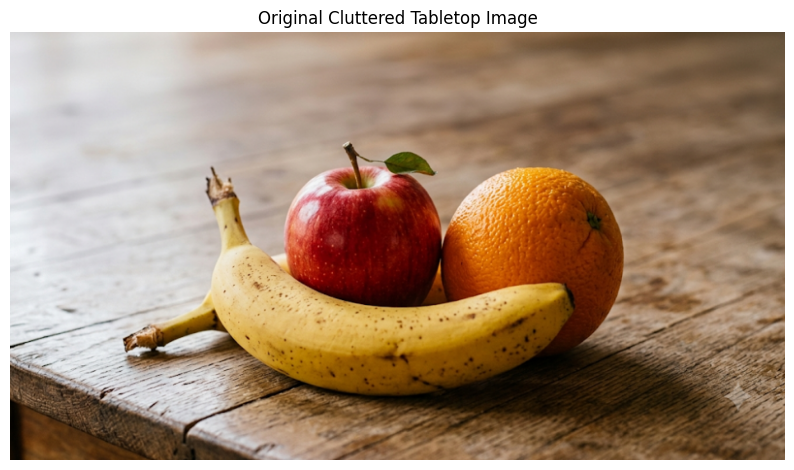

In [ ]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image:", image_path)
print("Image shape:", img_rgb.shape)

plt.figure(figsize=(10, 7))
plt.imshow(img_rgb)
plt.title("Original Cluttered Tabletop Image")
plt.axis("off")
plt.show()

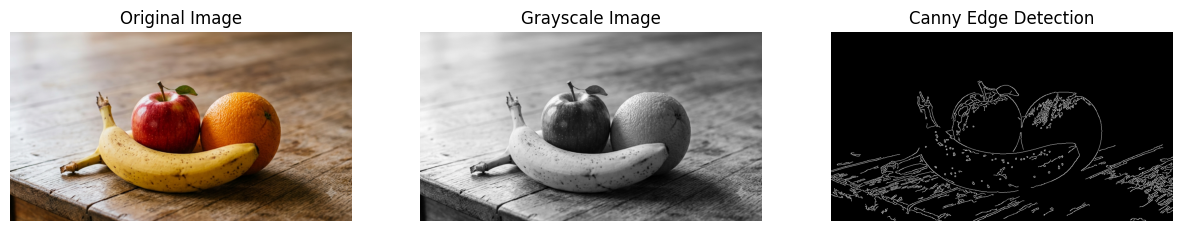

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 1.0)

# Canny edge detection
edges = cv2.Canny(blur, 50, 150)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.show()

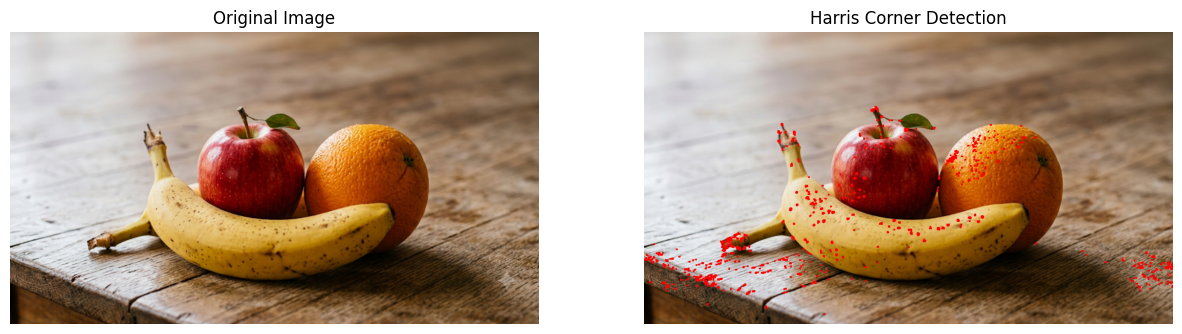

In [ ]:
gray_float = np.float32(gray)

# Harris corner detection
harris = cv2.cornerHarris(
    gray_float,
    blockSize=2,
    ksize=3,
    k=0.04
)

# Dilate for better visualization
harris_dilated = cv2.dilate(harris, None)

# Copy original image
harris_result = img_rgb.copy()

# Mark strong corners
threshold = 0.01 * harris_dilated.max()

harris_result[harris_dilated > threshold] = [255, 0, 0]

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(harris_result)
plt.title("Harris Corner Detection")
plt.axis("off")

plt.show()

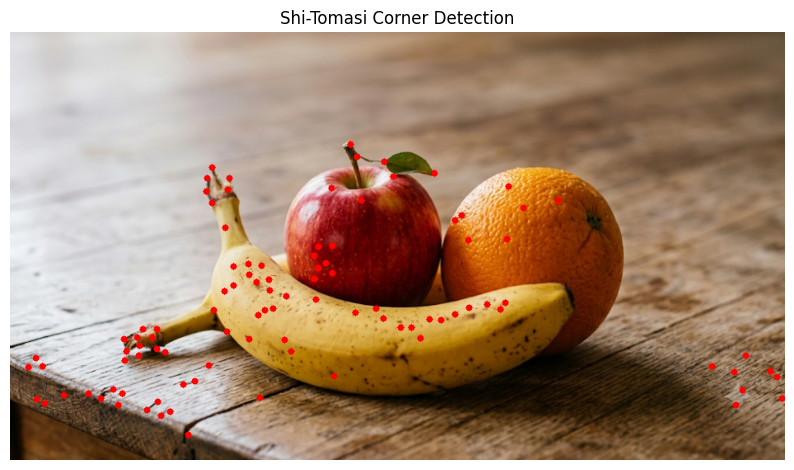

In [ ]:
corners = cv2.goodFeaturesToTrack(
    gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10
)

shi_tomasi = img_rgb.copy()

if corners is not None:
    corners = np.int32(corners)

    for corner in corners:
        x, y = corner.ravel()
        cv2.circle(shi_tomasi, (x, y), 4, (255, 0, 0), -1)

plt.figure(figsize=(10, 7))
plt.imshow(shi_tomasi)
plt.title("Shi-Tomasi Corner Detection")
plt.axis("off")
plt.show()

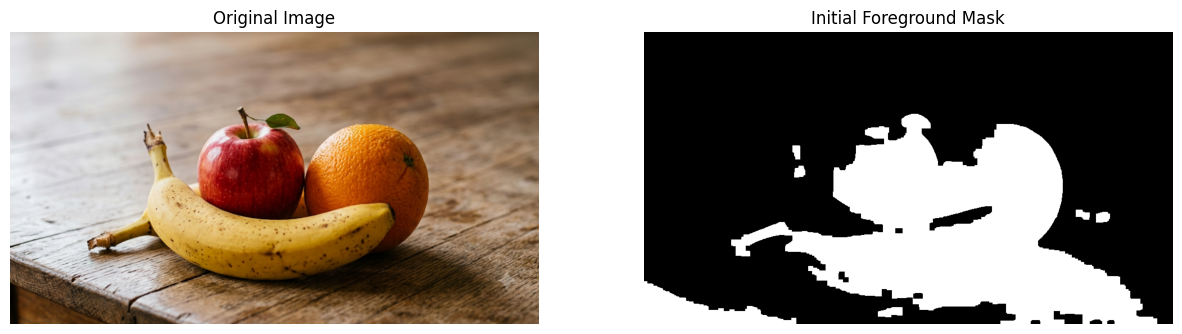

In [ ]:
# Convert RGB image to HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Use saturation to separate colorful fruits from low-saturation background
sat = hsv[:, :, 1]

# Otsu threshold
_, binary = cv2.threshold(
    sat,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((5, 5), np.uint8)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=2
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Initial Foreground Mask")
plt.axis("off")

plt.show()

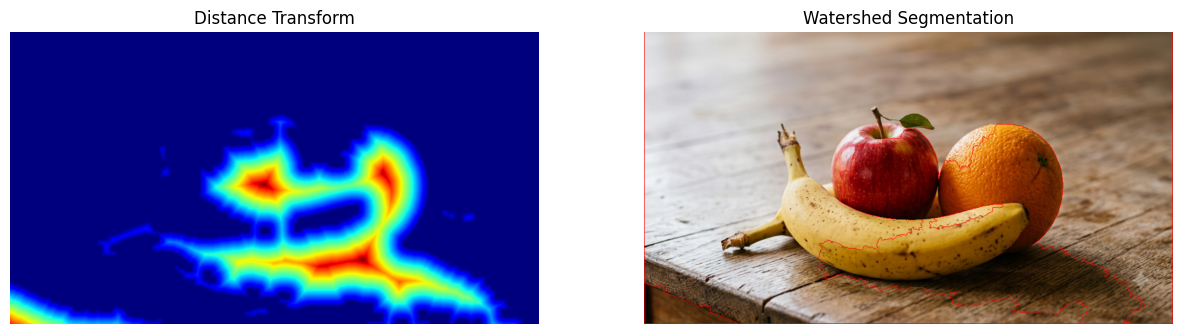

In [ ]:
# Sure foreground
dist = cv2.distanceTransform(binary, cv2.DIST_L2, 5)

_, sure_fg = cv2.threshold(
    dist,
    0.35 * dist.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Sure background
sure_bg = cv2.dilate(binary, kernel, iterations=3)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labeling
num_markers, markers = cv2.connectedComponents(sure_fg)

# Add 1 because watershed reserves label 0
markers = markers + 1

# Unknown region = 0
markers[unknown == 255] = 0

# Apply watershed
watershed_img = img_rgb.copy()

markers = cv2.watershed(
    cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR),
    markers
)

# Boundary pixels become -1
watershed_result = img_rgb.copy()
watershed_result[markers == -1] = [255, 0, 0]

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(dist, cmap="jet")
plt.title("Distance Transform")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watershed_result)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.show()

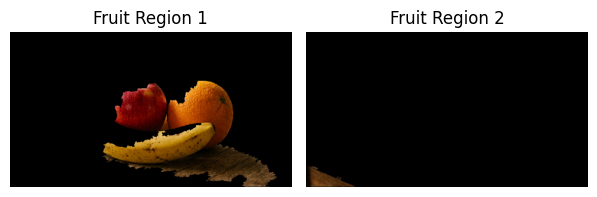

Detected regions: 2


In [ ]:
labels = np.unique(markers)

plt.figure(figsize=(12, 8))

count = 0

for label in labels:
    if label <= 1:
        continue

    region = np.zeros_like(img_rgb)

    region[markers == label] = img_rgb[markers == label]

    if np.sum(markers == label) < 500:
        continue

    count += 1

    plt.subplot(3, 4, count)
    plt.imshow(region)
    plt.title(f"Fruit Region {count}")
    plt.axis("off")

    if count >= 12:
        break

plt.tight_layout()
plt.show()

print("Detected regions:", count)

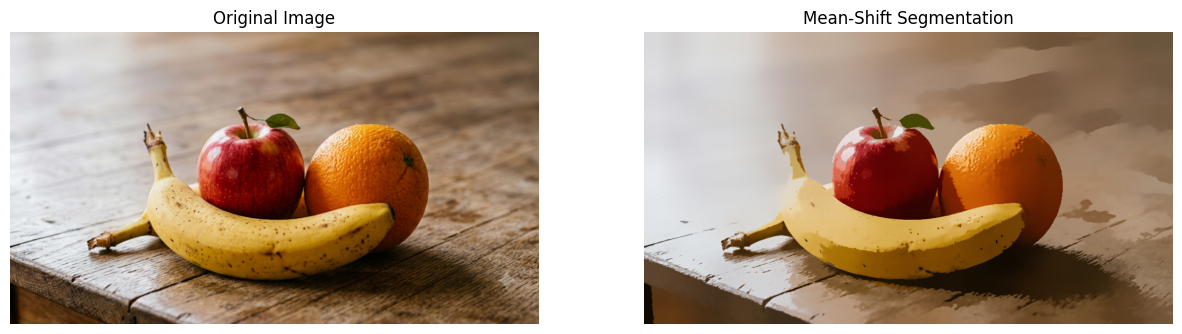

In [ ]:
# Convert image to BGR for OpenCV
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

# Mean-shift parameters
sp = 25
sr = 40

mean_shift = cv2.pyrMeanShiftFiltering(
    img_bgr,
    sp=sp,
    sr=sr
)

mean_shift_rgb = cv2.cvtColor(
    mean_shift,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mean_shift_rgb)
plt.title("Mean-Shift Segmentation")
plt.axis("off")

plt.show()

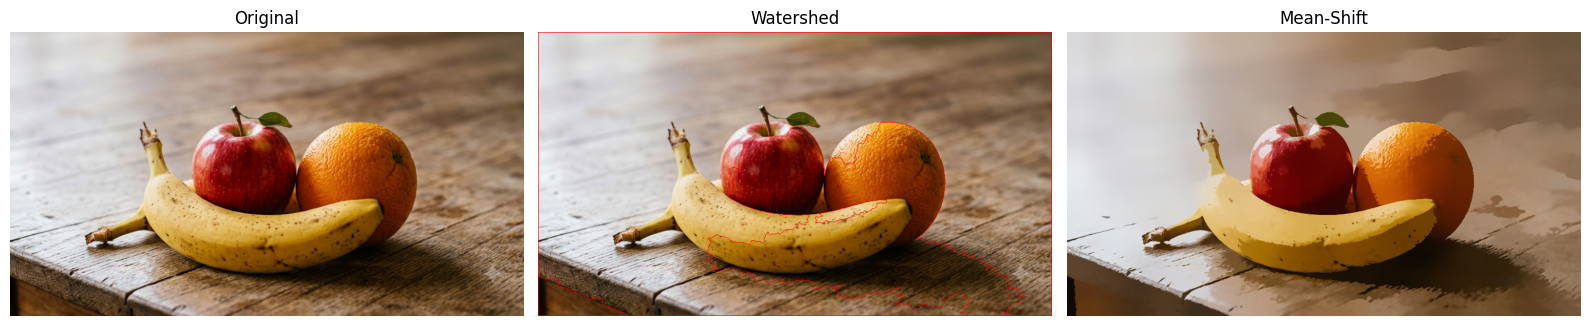

In [ ]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(watershed_result)
plt.title("Watershed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mean_shift_rgb)
plt.title("Mean-Shift")
plt.axis("off")

plt.tight_layout()
plt.show()

Number of SIFT keypoints: 1799
Descriptor shape: (1799, 128)


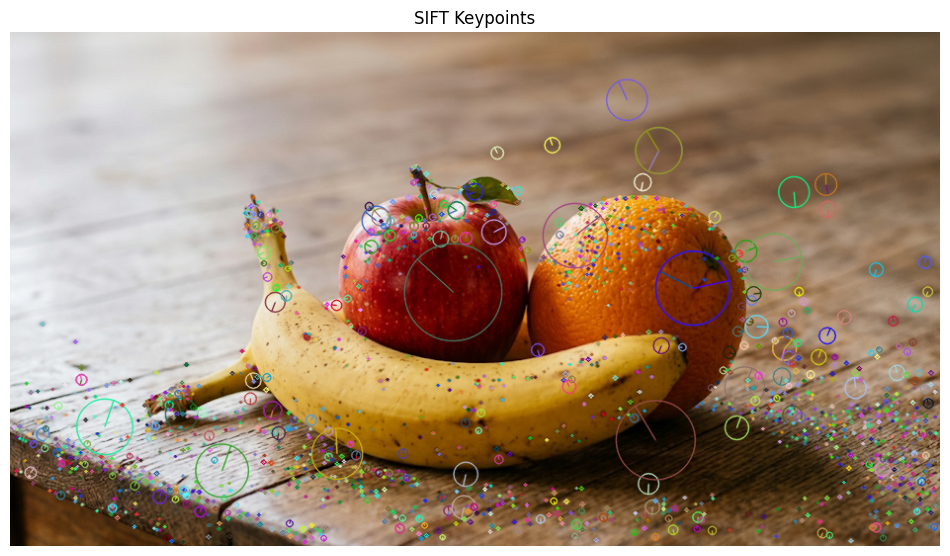

In [ ]:
# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and descriptors
keypoints, descriptors = sift.detectAndCompute(
    gray,
    None
)

print("Number of SIFT keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape if descriptors is not None else None)

# Draw keypoints
sift_image = cv2.drawKeypoints(
    img_rgb,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(12, 8))
plt.imshow(sift_image)
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

In [ ]:
fruit_features = []

unique_labels = np.unique(markers)

for label in unique_labels:

    if label <= 1:
        continue

    mask = np.uint8(markers == label) * 255

    # Ignore very small regions
    if cv2.countNonZero(mask) < 1000:
        continue

    # Extract region
    region = cv2.bitwise_and(
        gray,
        gray,
        mask=mask
    )

    kp, des = sift.detectAndCompute(
        region,
        mask
    )

    fruit_features.append({
        "label": int(label),
        "keypoints": kp,
        "descriptors": des
    })

for i, feature_data in enumerate(fruit_features):
    des = feature_data["descriptors"]

    print(
        f"Fruit Region {i+1}: "
        f"{len(feature_data['keypoints'])} keypoints"
    )

Fruit Region 1: 432 keypoints
Fruit Region 2: 7 keypoints


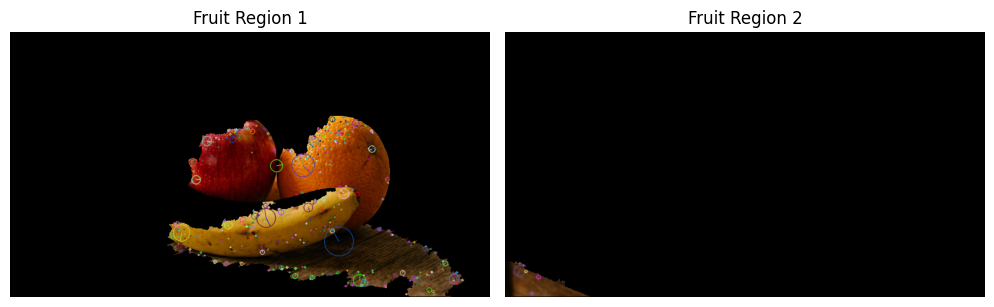

In [ ]:
display_count = min(len(fruit_features), 6)

plt.figure(figsize=(15, 8))

plot_index = 1

for i in range(display_count):

    label = fruit_features[i]["label"]

    mask = np.uint8(markers == label) * 255

    region = cv2.bitwise_and(
        img_rgb,
        img_rgb,
        mask=mask
    )

    kp = fruit_features[i]["keypoints"]

    result = cv2.drawKeypoints(
        region,
        kp,
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    plt.subplot(2, 3, plot_index)
    plt.imshow(result)
    plt.title(f"Fruit Region {i+1}")
    plt.axis("off")

    plot_index += 1

plt.tight_layout()
plt.show()

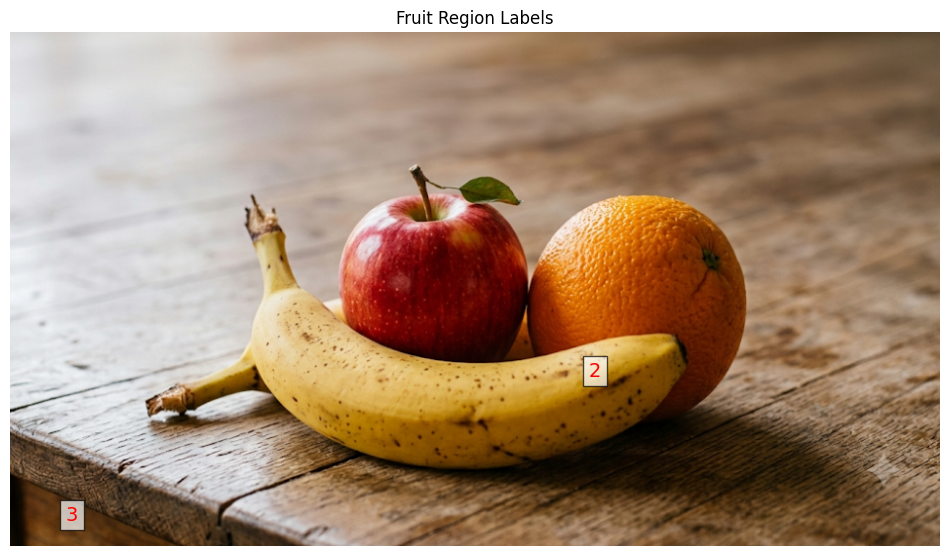

In [ ]:
plt.figure(figsize=(12, 8))

plt.imshow(img_rgb)

for region in measure.regionprops(markers):
    if region.label <= 1:
        continue

    if region.area < 1000:
        continue

    y, x = region.centroid

    plt.text(
        x,
        y,
        str(region.label),
        fontsize=14,
        color="red",
        bbox=dict(facecolor="white", alpha=0.7)
    )

plt.title("Fruit Region Labels")
plt.axis("off")
plt.show()

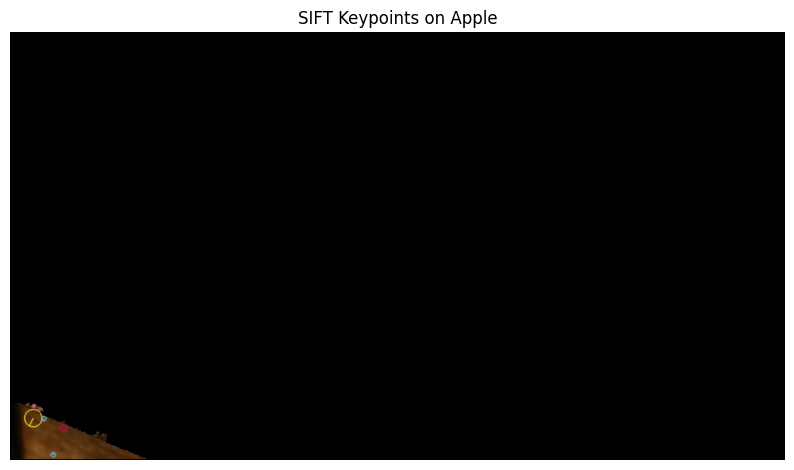

Apple keypoints: 7
Apple descriptor shape: (7, 128)


In [ ]:
apple_label = 3

apple_mask = np.uint8(markers == apple_label) * 255

apple = cv2.bitwise_and(
    img_rgb,
    img_rgb,
    mask=apple_mask
)

apple_gray = cv2.cvtColor(
    apple,
    cv2.COLOR_RGB2GRAY
)

apple_kp, apple_des = sift.detectAndCompute(
    apple_gray,
    apple_mask
)

apple_features = cv2.drawKeypoints(
    apple,
    apple_kp,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 8))
plt.imshow(apple_features)
plt.title("SIFT Keypoints on Apple")
plt.axis("off")
plt.show()

print("Apple keypoints:", len(apple_kp))
print("Apple descriptor shape:", apple_des.shape if apple_des is not None else None)

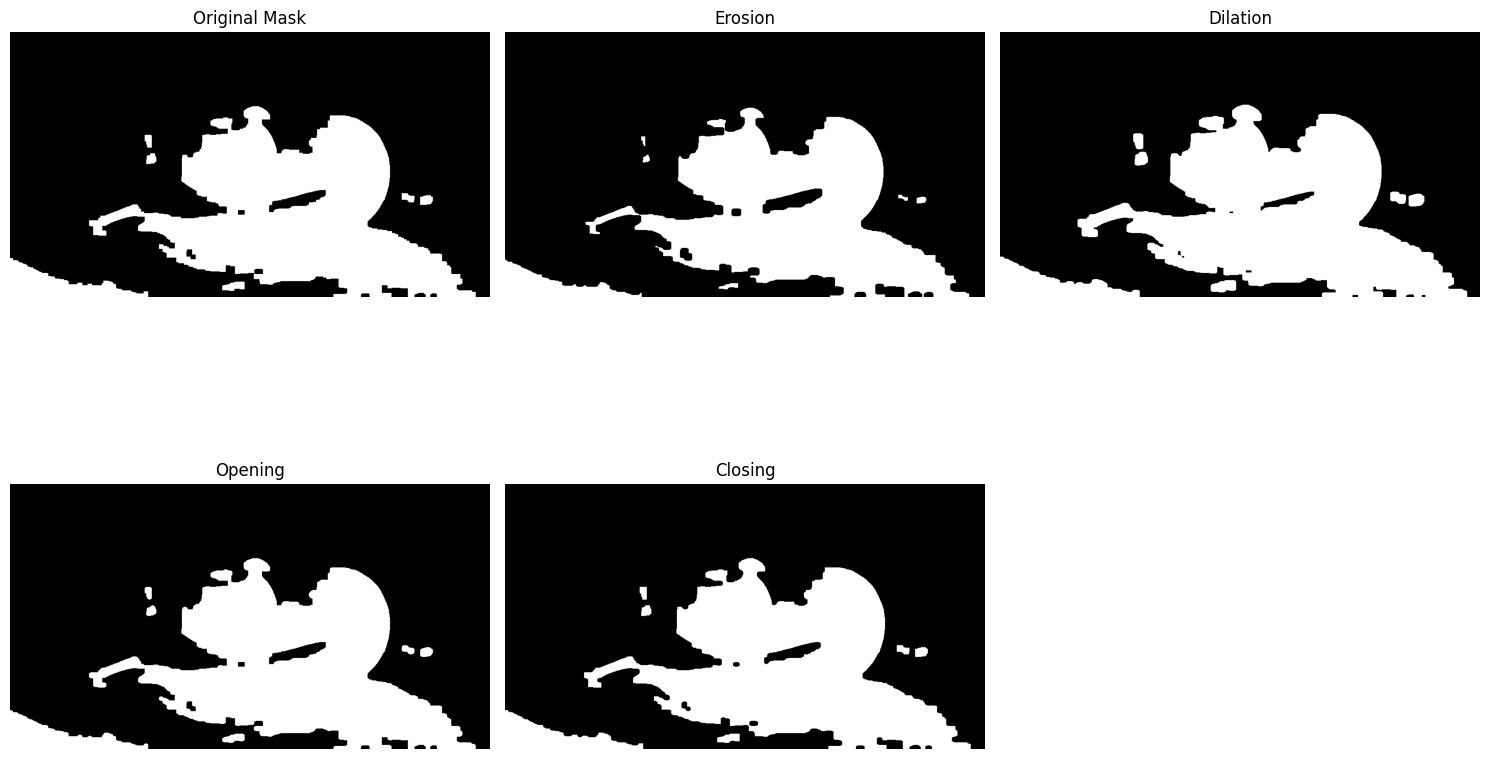

In [ ]:
# Use the binary foreground mask
mask = binary.copy()

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (7, 7)
)

# Erosion
erosion = cv2.erode(
    mask,
    kernel,
    iterations=1
)

# Dilation
dilation = cv2.dilate(
    mask,
    kernel,
    iterations=1
)

# Opening = erosion followed by dilation
opening = cv2.morphologyEx(
    mask,
    cv2.MORPH_OPEN,
    kernel
)

# Closing = dilation followed by erosion
closing = cv2.morphologyEx(
    mask,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

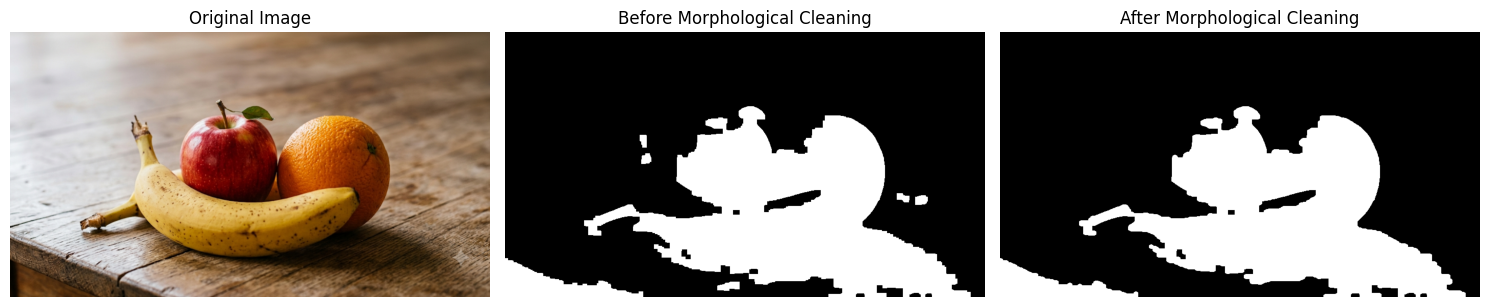

In [ ]:
# Remove small components
num_labels, labels_clean, stats, centroids = cv2.connectedComponentsWithStats(
    opening,
    connectivity=8
)

clean_mask = np.zeros_like(opening)

min_area = 1000

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= min_area:
        clean_mask[labels_clean == i] = 255

plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Before Morphological Cleaning")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clean_mask, cmap="gray")
plt.title("After Morphological Cleaning")
plt.axis("off")

plt.tight_layout()
plt.show()

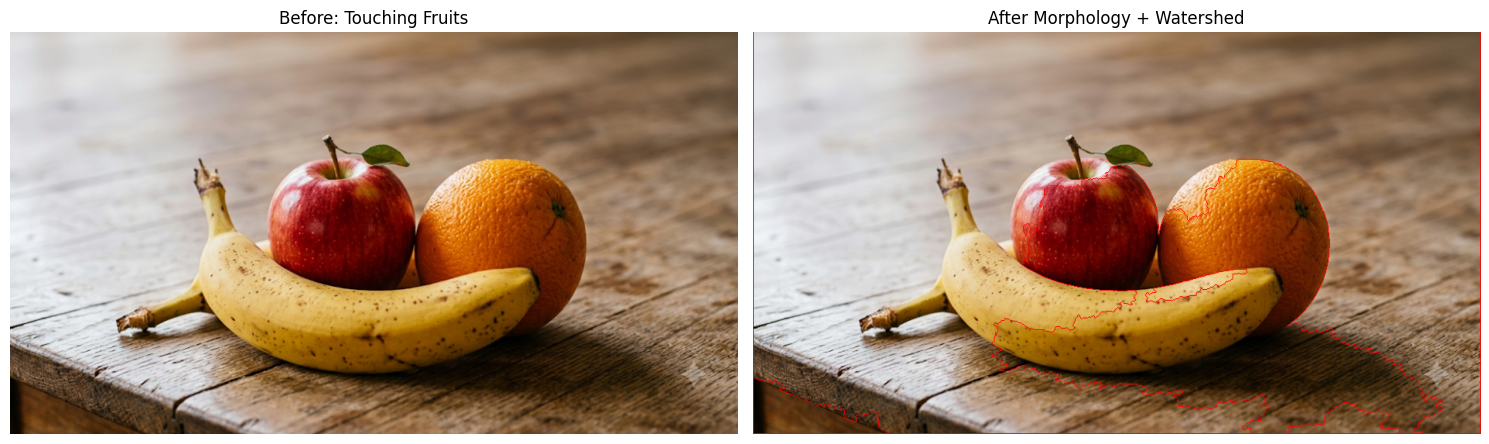

In [ ]:
# Clean mask
clean = clean_mask

# Distance transform
distance = cv2.distanceTransform(
    clean,
    cv2.DIST_L2,
    5
)

# Detect fruit centers
_, foreground = cv2.threshold(
    distance,
    0.35 * distance.max(),
    255,
    cv2.THRESH_BINARY
)

foreground = np.uint8(foreground)

# Background
background = cv2.dilate(
    clean,
    kernel,
    iterations=3
)

# Unknown region
unknown = cv2.subtract(
    background,
    foreground
)

# Markers
num_markers, markers_final = cv2.connectedComponents(
    foreground
)

markers_final = markers_final + 1

markers_final[unknown == 255] = 0

# Watershed
result_final = cv2.cvtColor(
    img_rgb.copy(),
    cv2.COLOR_RGB2BGR
)

markers_final = cv2.watershed(
    result_final,
    markers_final
)

result_final = cv2.cvtColor(
    result_final,
    cv2.COLOR_BGR2RGB
)

# Mark boundaries
result_final[markers_final == -1] = [255, 0, 0]

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Before: Touching Fruits")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_final)
plt.title("After Morphology + Watershed")
plt.axis("off")

plt.tight_layout()
plt.show()